# Caso 2: Reconocimiento de rostros con Eigenfaces
**Actividad 05 · Aprendizaje de Máquina · UNAP**

Construimos una galería de rostros conocidos y buscamos en ella el más parecido a cada consulta.
PCA se ajusta solo con la galería y sin identidades. Las identidades se usan para evaluar la búsqueda
y los agrupamientos, no para ajustar PCA ni para formar los grupos.

1. Separamos 320 rostros para la galería y 80 para las consultas.
2. Elegimos el menor número de componentes que conserva al menos el 90% de la varianza.
3. Comparamos distancias euclídeas y coseno en píxeles y en el espacio de PCA.
4. Revisamos top-1, top-5 y dos agrupamientos no supervisados.


In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.datasets import fetch_olivetti_faces
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    homogeneity_score,
    normalized_mutual_info_score,
    pairwise_distances,
    silhouette_score,
)
from sklearn.model_selection import train_test_split

SEMILLA = 42
DATOS_HOME = "datos_sklearn"
os.makedirs("figuras", exist_ok=True)
os.makedirs("resultados", exist_ok=True)


def pct(valor):
    return f"{valor * 100:.1f}%"


## 1. Galería y consultas

La partición estratificada deja ocho fotos por persona en la galería y dos en las consultas.
La identidad devuelta será la de la foto de galería más cercana; la identidad de cada consulta
se reserva para evaluar el resultado.


In [2]:
caras = fetch_olivetti_faces(
    shuffle=False,
    data_home=DATOS_HOME,
)
imagenes = caras.images
pixeles = caras.data
identidades = caras.target
indices = np.arange(len(identidades))

indices_galeria, indices_consultas = train_test_split(
    indices,
    test_size=0.2,
    stratify=identidades,
    random_state=SEMILLA,
)
galeria = pixeles[indices_galeria]
consultas = pixeles[indices_consultas]
identidades_galeria = identidades[indices_galeria]
identidades_consultas = identidades[indices_consultas]

print(
    f"Imágenes: {len(pixeles)} | personas: {len(np.unique(identidades))} | "
    f"píxeles por imagen: {pixeles.shape[1]}"
)
print(
    f"Galería: {galeria.shape[0]} rostros | consultas: {consultas.shape[0]} rostros"
)


Imágenes: 400 | personas: 40 | píxeles por imagen: 4096
Galería: 320 rostros | consultas: 80 rostros


## 2. PCA y eigenfaces

Ajustamos PCA únicamente con los píxeles de la galería. La media y las direcciones principales
se calculan sin pasar las identidades al método.


In [3]:
pca = PCA(svd_solver="full")
coordenadas_galeria_completas = pca.fit_transform(galeria)
coordenadas_consultas_completas = pca.transform(consultas)
varianza_acumulada = np.cumsum(pca.explained_variance_ratio_)
n90 = int(np.searchsorted(varianza_acumulada, 0.90) + 1)
n95 = int(np.searchsorted(varianza_acumulada, 0.95) + 1)
varianza_n90 = float(varianza_acumulada[n90 - 1])
varianza_n95 = float(varianza_acumulada[n95 - 1])

coordenadas_galeria = coordenadas_galeria_completas[:, :n90]
coordenadas_consultas = coordenadas_consultas_completas[:, :n90]

print(
    f"Para alcanzar 90% usamos {n90} componentes "
    f"({pct(varianza_n90)} de varianza)."
)
print(
    f"Para alcanzar 95% se necesitan {n95} componentes "
    f"({pct(varianza_n95)} de varianza)."
)
print(f"La representación pasa de {galeria.shape[1]} a {n90} dimensiones.")


Para alcanzar 90% usamos 62 componentes (90.0% de varianza).
Para alcanzar 95% se necesitan 111 componentes (95.0% de varianza).
La representación pasa de 4096 a 62 dimensiones.


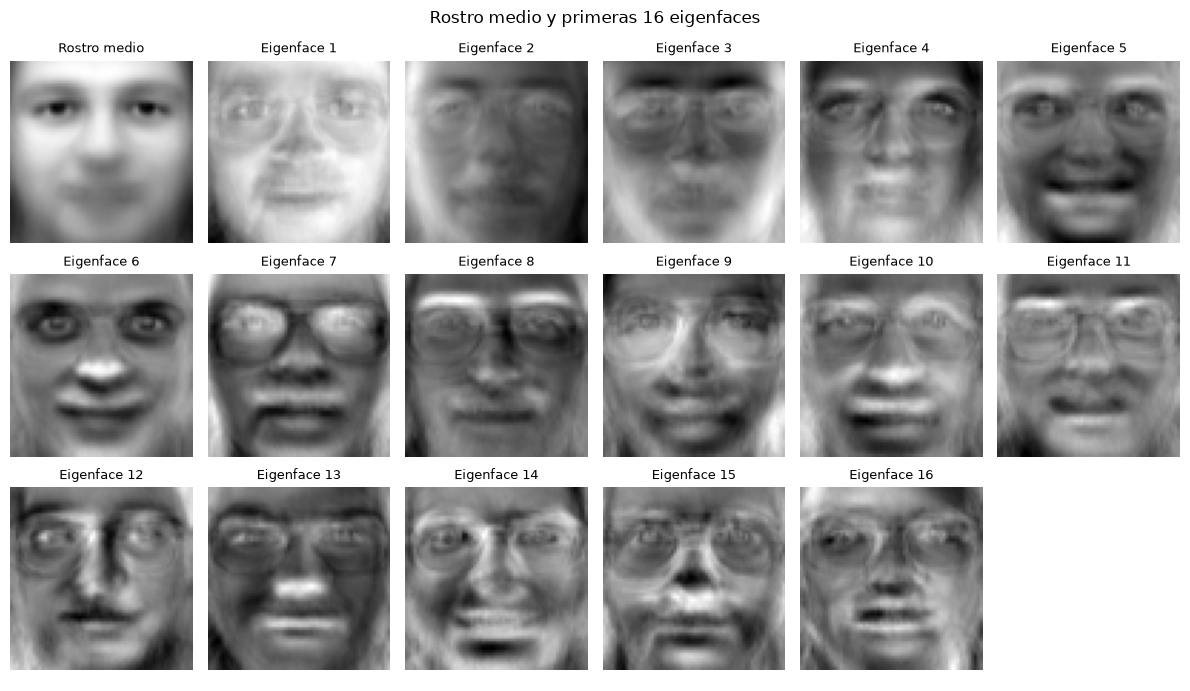

In [4]:
fig, ejes = plt.subplots(3, 6, figsize=(12, 7))
ejes = ejes.ravel()
ejes[0].imshow(pca.mean_.reshape(64, 64), cmap="gray")
ejes[0].set_title("Rostro medio", fontsize=9)
for indice, eje in enumerate(ejes[1:17]):
    eje.imshow(pca.components_[indice].reshape(64, 64), cmap="gray")
    eje.set_title(f"Eigenface {indice + 1}", fontsize=9)
for eje in ejes:
    eje.axis("off")
fig.suptitle("Rostro medio y primeras 16 eigenfaces")
fig.tight_layout()
fig.savefig("figuras/caso2_eigenfaces.png", dpi=150, bbox_inches="tight")
plt.show()


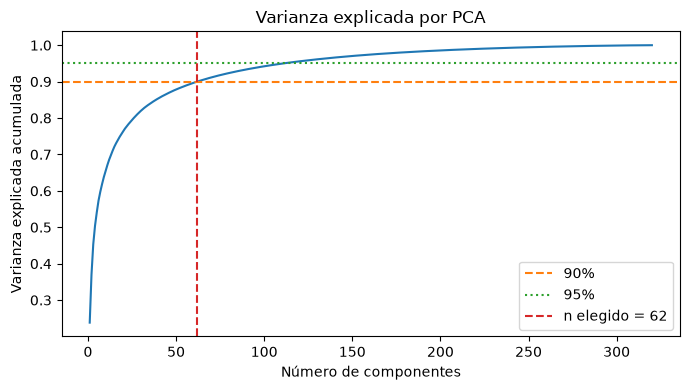

In [5]:
fig, eje = plt.subplots(figsize=(7, 4))
eje.plot(np.arange(1, len(varianza_acumulada) + 1), varianza_acumulada)
eje.axhline(0.90, linestyle="--", color="tab:orange", label="90%")
eje.axhline(0.95, linestyle=":", color="tab:green", label="95%")
eje.axvline(n90, linestyle="--", color="tab:red", label=f"n elegido = {n90}")
eje.set_xlabel("Número de componentes")
eje.set_ylabel("Varianza explicada acumulada")
eje.set_title("Varianza explicada por PCA")
eje.legend()
fig.tight_layout()
fig.savefig("figuras/caso2_varianza.png", dpi=150, bbox_inches="tight")
plt.show()


Cada componente de PCA es una dirección de variación de las caras; al mostrarla como imagen
obtenemos una eigenface. Para reconstruir, proyectamos una consulta y conservamos sus primeros
componentes. Así vemos qué detalle se pierde al comprimir.


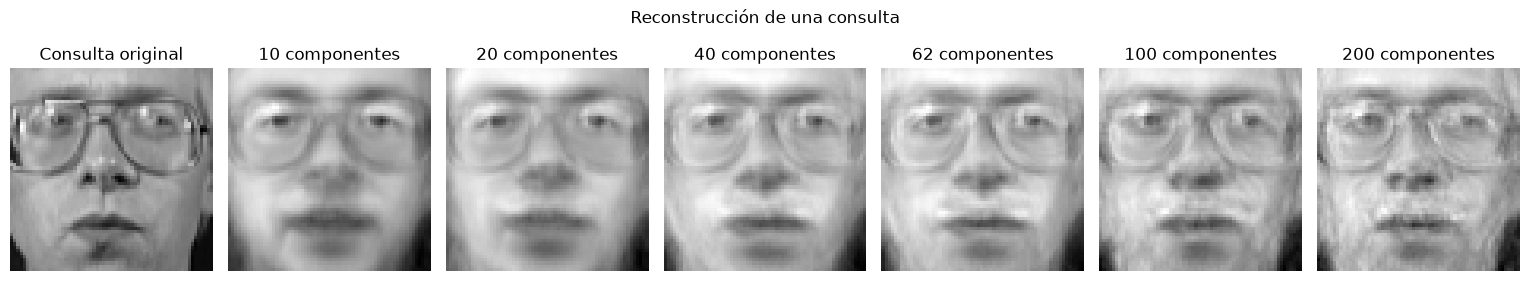

In [6]:
indice_consulta_reconstruccion = 0
consulta_reconstruccion = consultas[indice_consulta_reconstruccion]
valores_reconstruccion = sorted(
    {n for n in (10, 20, 40, n90, 100, 200) if n <= pca.n_components_}
)
fig, ejes = plt.subplots(
    1,
    len(valores_reconstruccion) + 1,
    figsize=(2.2 * (len(valores_reconstruccion) + 1), 3),
)
ejes[0].imshow(consulta_reconstruccion.reshape(64, 64), cmap="gray")
ejes[0].set_title("Consulta original")
coordenadas_reconstruccion = pca.transform(
    consulta_reconstruccion.reshape(1, -1)
)[0]
for eje, n in zip(ejes[1:], valores_reconstruccion):
    reconstruccion = (
        pca.mean_
        + coordenadas_reconstruccion[:n] @ pca.components_[:n]
    )
    eje.imshow(reconstruccion.reshape(64, 64), cmap="gray")
    eje.set_title(f"{n} componentes")
for eje in ejes:
    eje.axis("off")
fig.suptitle("Reconstrucción de una consulta")
fig.tight_layout()
fig.savefig("figuras/caso2_reconstruccion.png", dpi=150, bbox_inches="tight")
plt.show()


## 3. Reconocimiento por distancia

En el espacio de eigenfaces, cada rostro es un vector de coordenadas. La distancia mide qué tan
separados quedan dos vectores: menor distancia significa mayor parecido según la representación.
En el método clásico de Eigenfaces, la identidad se consulta en la galería del rostro más cercano;
no se ajusta un clasificador. Turk y Pentland (1991) describieron este reconocimiento mediante
proyección al espacio de caras y comparación con rostros conocidos.

Top-1 cuenta una consulta correcta si la galería más cercana tiene su identidad. Top-5 cuenta una
consulta correcta si esa identidad aparece entre las cinco galerías más cercanas. Las etiquetas
de las consultas se usan solo para calcular estas métricas.


In [7]:
def medir_busqueda(datos_galeria, datos_consultas, metrica):
    distancias = pairwise_distances(
        datos_consultas,
        datos_galeria,
        metric=metrica,
    )
    orden = np.argsort(distancias, axis=1)
    identidades_top1 = identidades_galeria[orden[:, 0]]
    aciertos_top1 = identidades_top1 == identidades_consultas
    identidades_top5 = identidades_galeria[orden[:, :5]]
    aciertos_top5 = np.any(
        identidades_top5 == identidades_consultas[:, np.newaxis],
        axis=1,
    )
    return {
        "distancias": distancias,
        "orden": orden,
        "identidades_top1": identidades_top1,
        "aciertos_top1": aciertos_top1,
        "aciertos_top5": aciertos_top5,
    }


representaciones = {
    "PCA": (coordenadas_galeria, coordenadas_consultas),
    "Píxeles": (galeria, consultas),
}
resultados_busqueda = {}
filas_busqueda = []

for nombre, (datos_galeria, datos_consultas) in representaciones.items():
    resultados_busqueda[nombre] = {}
    for metrica in ("euclidean", "cosine"):
        medicion = medir_busqueda(datos_galeria, datos_consultas, metrica)
        resultados_busqueda[nombre][metrica] = medicion
        top1 = int(medicion["aciertos_top1"].sum())
        top5 = int(medicion["aciertos_top5"].sum())
        filas_busqueda.append(
            {
                "Representación": nombre,
                "Distancia": "Euclídea" if metrica == "euclidean" else "Coseno",
                "Top-1": f"{top1}/{len(consultas)} ({pct(top1 / len(consultas))})",
                "Top-5": f"{top5}/{len(consultas)} ({pct(top5 / len(consultas))})",
            }
        )

tabla_busqueda = pd.DataFrame(filas_busqueda)
display(tabla_busqueda)


,Representación,Distancia,Top-1,Top-5
0,PCA,Euclídea,74/80 (92.5%),78/80 (97.5%)
1,PCA,Coseno,73/80 (91.2%),75/80 (93.8%)
2,Píxeles,Euclídea,74/80 (92.5%),78/80 (97.5%)
3,Píxeles,Coseno,74/80 (92.5%),77/80 (96.2%)


También mostramos resultados para otros tamaños de representación. Esta tabla es informativa:
no la usamos para elegir el número de componentes. La elección se hizo antes, con el umbral de
varianza explicado.


In [8]:
valores_n_informativos = sorted(
    {n for n in (10, 20, 40, 80, n90) if n <= pca.n_components_}
)
filas_n = []
resultados_por_n = []
for n in valores_n_informativos:
    for metrica in ("euclidean", "cosine"):
        medicion_n = medir_busqueda(
            coordenadas_galeria_completas[:, :n],
            coordenadas_consultas_completas[:, :n],
            metrica,
        )
        top1 = int(medicion_n["aciertos_top1"].sum())
        top5 = int(medicion_n["aciertos_top5"].sum())
        filas_n.append(
            {
                "Componentes": n,
                "Distancia": "Euclídea" if metrica == "euclidean" else "Coseno",
                "Top-1": f"{top1}/{len(consultas)} ({pct(top1 / len(consultas))})",
                "Top-5": f"{top5}/{len(consultas)} ({pct(top5 / len(consultas))})",
            }
        )
        resultados_por_n.append(
            {
                "componentes": n,
                "distancia": metrica,
                "top1_aciertos": top1,
                "top1_total": len(consultas),
                "top1_exactitud": top1 / len(consultas),
                "top5_aciertos": top5,
                "top5_total": len(consultas),
                "top5_exactitud": top5 / len(consultas),
            }
        )
display(pd.DataFrame(filas_n))


,Componentes,Distancia,Top-1,Top-5
0,10,Euclídea,70/80 (87.5%),77/80 (96.2%)
1,10,Coseno,69/80 (86.2%),75/80 (93.8%)
2,20,Euclídea,73/80 (91.2%),77/80 (96.2%)
3,20,Coseno,71/80 (88.8%),76/80 (95.0%)
4,40,Euclídea,73/80 (91.2%),78/80 (97.5%)
5,40,Coseno,73/80 (91.2%),75/80 (93.8%)
6,62,Euclídea,74/80 (92.5%),78/80 (97.5%)
7,62,Coseno,73/80 (91.2%),75/80 (93.8%)
8,80,Euclídea,74/80 (92.5%),78/80 (97.5%)
9,80,Coseno,73/80 (91.2%),76/80 (95.0%)


## 4. Revisión de consultas

`reconocer(i)` recibe el índice de una consulta entre 0 y 79. Devuelve la identidad de la galería
más cercana y muestra las cinco opciones, su distancia y si cada identidad coincide con la consulta.
El color verde indica coincidencia y el rojo, una identidad distinta.


Consulta 0: identidad devuelta 1; identidad real 1; acierto.


,posición,identidad,distancia,correcta
0,1,1,4.068488,True
1,2,1,4.231839,True
2,3,1,4.687805,True
3,4,1,5.537379,True
4,5,1,5.713799,True


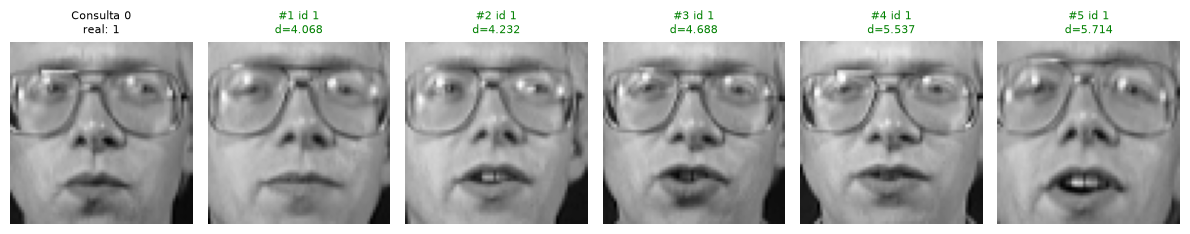

Consulta 8: identidad devuelta 39; identidad real 3; error.


,posición,identidad,distancia,correcta
0,1,39,5.174222,False
1,2,12,5.539291,False
2,3,39,5.931656,False
3,4,22,6.017055,False
4,5,12,6.112428,False


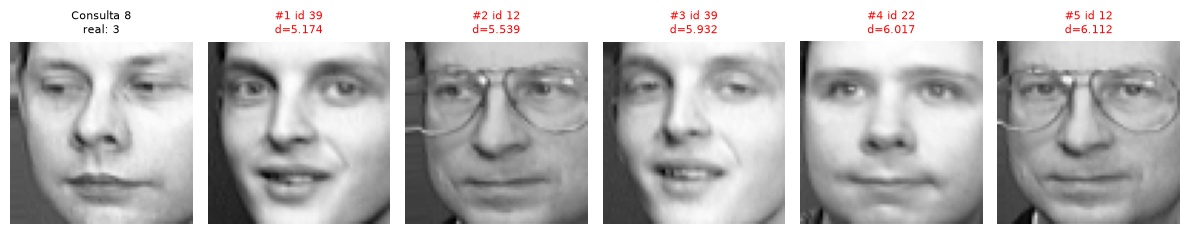

(39, False)

In [9]:
def reconocer(i):
    if not isinstance(i, (int, np.integer)) or not 0 <= i < len(consultas):
        raise IndexError("El índice debe estar entre 0 y 79.")
    medicion = resultados_busqueda["PCA"]["euclidean"]
    orden = medicion["orden"][i, :5]
    identidad_real = int(identidades_consultas[i])
    identidad_devuelta = int(identidades_galeria[orden[0]])
    acierto = identidad_devuelta == identidad_real

    print(
        f"Consulta {i}: identidad devuelta {identidad_devuelta}; "
        f"identidad real {identidad_real}; "
        f"{'acierto' if acierto else 'error'}."
    )
    datos_opciones = []
    for posicion, indice_galeria in enumerate(orden, start=1):
        datos_opciones.append(
            {
                "posición": posicion,
                "identidad": int(identidades_galeria[indice_galeria]),
                "distancia": float(medicion["distancias"][i, indice_galeria]),
                "correcta": bool(
                    identidades_galeria[indice_galeria] == identidad_real
                ),
            }
        )
    display(pd.DataFrame(datos_opciones))

    fig, ejes = plt.subplots(1, 6, figsize=(12, 2.7))
    ejes[0].imshow(imagenes[indices_consultas[i]], cmap="gray")
    ejes[0].set_title(f"Consulta {i}\nreal: {identidad_real}", fontsize=8)
    for eje in ejes:
        eje.axis("off")
    for eje, indice_galeria, opcion in zip(ejes[1:], orden, datos_opciones):
        color = "green" if opcion["correcta"] else "red"
        eje.imshow(imagenes[indices_galeria[indice_galeria]], cmap="gray")
        eje.set_title(
            f"#{opcion['posición']} id {opcion['identidad']}\n"
            f"d={opcion['distancia']:.3f}",
            fontsize=8,
            color=color,
        )
        for borde in eje.spines.values():
            borde.set_visible(True)
            borde.set_edgecolor(color)
            borde.set_linewidth(2)
    fig.tight_layout()
    plt.show()
    return identidad_devuelta, acierto


predicciones_pca_euclidea = resultados_busqueda["PCA"]["euclidean"][
    "identidades_top1"
]
indices_acierto = np.flatnonzero(predicciones_pca_euclidea == identidades_consultas)
indices_error = np.flatnonzero(predicciones_pca_euclidea != identidades_consultas)
if len(indices_acierto) == 0 or len(indices_error) == 0:
    raise RuntimeError("No se encontraron ambos ejemplos para la demostración.")
indice_acierto = int(indices_acierto[0])
indice_error = int(indices_error[0])
reconocer(indice_acierto)
reconocer(indice_error)


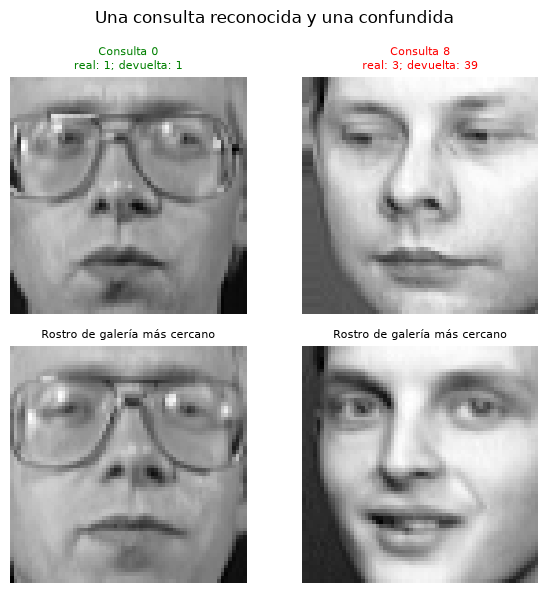

In [10]:
fig, ejes = plt.subplots(2, 2, figsize=(6, 6))
for columna, indice_consulta in enumerate((indice_acierto, indice_error)):
    identidad_real = int(identidades_consultas[indice_consulta])
    identidad_devuelta = int(predicciones_pca_euclidea[indice_consulta])
    color = "green" if identidad_real == identidad_devuelta else "red"
    indice_galeria_devuelto = int(
        resultados_busqueda["PCA"]["euclidean"]["orden"][indice_consulta, 0]
    )
    ejes[0, columna].imshow(
        imagenes[indices_consultas[indice_consulta]],
        cmap="gray",
    )
    ejes[0, columna].set_title(
        f"Consulta {indice_consulta}\nreal: {identidad_real}; devuelta: {identidad_devuelta}",
        fontsize=8,
        color=color,
    )
    ejes[1, columna].imshow(
        imagenes[indices_galeria[indice_galeria_devuelto]],
        cmap="gray",
    )
    ejes[1, columna].set_title("Rostro de galería más cercano", fontsize=8)
    for eje in (ejes[0, columna], ejes[1, columna]):
        eje.axis("off")
        for borde in eje.spines.values():
            borde.set_visible(True)
            borde.set_edgecolor(color)
            borde.set_linewidth(2)
fig.suptitle("Una consulta reconocida y una confundida")
fig.tight_layout()
fig.savefig("figuras/caso2_aciertos_errores.png", dpi=150, bbox_inches="tight")
plt.show()


## 5. Agrupamiento no supervisado

Agrupamos las coordenadas PCA de las 400 imágenes sin entregar identidades a los métodos.
Las identidades reales se consultan únicamente para las métricas externas; la silueta se calcula
con las coordenadas PCA y los grupos obtenidos.


In [11]:
coordenadas_todas = pca.transform(pixeles)[:, :n90]
etiquetas_grupos = {
    "K-means": KMeans(
        n_clusters=40,
        n_init=10,
        random_state=SEMILLA,
    ).fit_predict(coordenadas_todas),
    "Jerárquico (ward)": AgglomerativeClustering(
        n_clusters=40,
        linkage="ward",
    ).fit_predict(coordenadas_todas),
}

metricas_agrupamiento = {}
filas_agrupamiento = []
for nombre, etiquetas in etiquetas_grupos.items():
    ari = float(adjusted_rand_score(identidades, etiquetas))
    nmi = float(normalized_mutual_info_score(identidades, etiquetas))
    homogeneidad = float(homogeneity_score(identidades, etiquetas))
    silueta = float(silhouette_score(coordenadas_todas, etiquetas))
    metricas_agrupamiento[nombre] = {
        "ari": ari,
        "nmi": nmi,
        "homogeneidad": homogeneidad,
        "silueta": silueta,
    }
    filas_agrupamiento.append(
        {
            "Método": nombre,
            "ARI": f"{ari:.3f}",
            "NMI": f"{nmi:.3f}",
            "Homogeneidad": f"{homogeneidad:.3f}",
            "Silueta": f"{silueta:.3f}",
        }
    )
display(pd.DataFrame(filas_agrupamiento))


,Método,ARI,NMI,Homogeneidad,Silueta
0,K-means,0.451,0.785,0.772,0.200
1,Jerárquico (ward),0.526,0.825,0.812,0.214


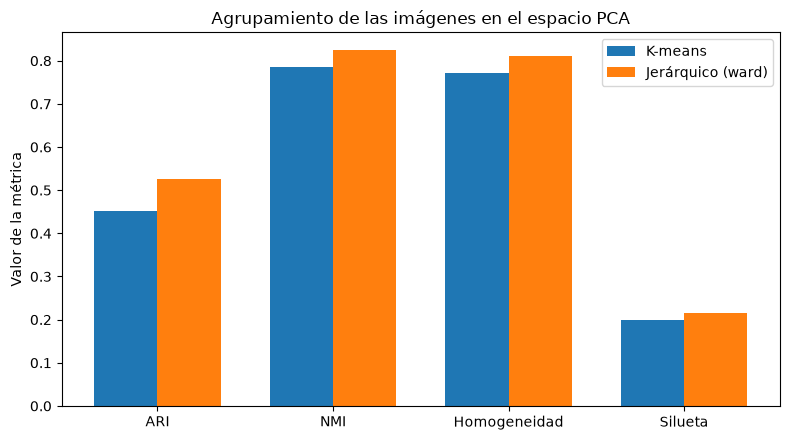

In [12]:
fig, eje = plt.subplots(figsize=(8, 4.5))
nombres_metricas = ("ARI", "NMI", "Homogeneidad", "Silueta")
nombres_metodos = tuple(metricas_agrupamiento)
ancho = 0.36
posiciones = np.arange(len(nombres_metricas))
for indice, nombre in enumerate(nombres_metodos):
    valores = [
        metricas_agrupamiento[nombre][clave]
        for clave in ("ari", "nmi", "homogeneidad", "silueta")
    ]
    eje.bar(
        posiciones + (indice - 0.5) * ancho,
        valores,
        ancho,
        label=nombre,
    )
eje.set_xticks(posiciones, nombres_metricas)
eje.set_ylabel("Valor de la métrica")
eje.set_title("Agrupamiento de las imágenes en el espacio PCA")
eje.legend()
fig.tight_layout()
fig.savefig("figuras/caso2_agrupamiento.png", dpi=150, bbox_inches="tight")
plt.show()


## 6. Ensayo orientativo con personas fuera de la galería

Reservamos cinco identidades para simular personas desconocidas. Sus etiquetas solo definen qué
consultas forman el ensayo y permiten evaluarlo; no entran al ajuste de PCA ni al umbral. El umbral
es el percentil 90 de las distancias al vecino más cercano de cada rostro de galería, sin contarse
a sí mismo. Hay solo diez consultas desconocidas, así que el resultado es orientativo.


In [13]:
personas_reservadas = np.random.RandomState(SEMILLA).choice(
    np.unique(identidades),
    size=5,
    replace=False,
)
mascara_galeria_conocida = ~np.isin(
    identidades_galeria,
    personas_reservadas,
)
mascara_consultas_desconocidas = np.isin(
    identidades_consultas,
    personas_reservadas,
)
galeria_conocida = galeria[mascara_galeria_conocida]
identidades_galeria_conocida = identidades_galeria[mascara_galeria_conocida]
consultas_conocidas = consultas[~mascara_consultas_desconocidas]
identidades_consultas_conocidas = identidades_consultas[
    ~mascara_consultas_desconocidas
]
consultas_desconocidas = consultas[mascara_consultas_desconocidas]

pca_conocidas = PCA(svd_solver="full")
z_galeria_conocida_full = pca_conocidas.fit_transform(galeria_conocida)
varianza_conocida = np.cumsum(pca_conocidas.explained_variance_ratio_)
n90_conocidas = int(np.searchsorted(varianza_conocida, 0.90) + 1)
z_galeria_conocida = z_galeria_conocida_full[:, :n90_conocidas]
z_consultas_conocidas = pca_conocidas.transform(consultas_conocidas)[
    :, :n90_conocidas
]
z_consultas_desconocidas = pca_conocidas.transform(consultas_desconocidas)[
    :, :n90_conocidas
]

distancias_galeria = pairwise_distances(
    z_galeria_conocida,
    z_galeria_conocida,
    metric="euclidean",
)
np.fill_diagonal(distancias_galeria, np.inf)
distancia_vecino_galeria = distancias_galeria.min(axis=1)
umbral_desconocido = float(np.percentile(distancia_vecino_galeria, 90))

distancias_conocidas = pairwise_distances(
    z_consultas_conocidas,
    z_galeria_conocida,
    metric="euclidean",
)
orden_conocidas = np.argsort(distancias_conocidas, axis=1)
distancia_min_conocidas = distancias_conocidas[
    np.arange(len(consultas_conocidas)),
    orden_conocidas[:, 0],
]
aceptadas_conocidas = distancia_min_conocidas <= umbral_desconocido
identidad_devuelta_conocidas = identidades_galeria_conocida[
    orden_conocidas[:, 0]
]
aciertos_aceptados = (
    identidad_devuelta_conocidas[aceptadas_conocidas]
    == identidades_consultas_conocidas[aceptadas_conocidas]
)

distancias_desconocidas = pairwise_distances(
    z_consultas_desconocidas,
    z_galeria_conocida,
    metric="euclidean",
)
distancia_min_desconocidas = distancias_desconocidas.min(axis=1)
desconocidas_rechazadas = distancia_min_desconocidas > umbral_desconocido

porcentaje_conocidas_aceptadas = float(aceptadas_conocidas.mean())
porcentaje_aciertos_aceptadas = float(
    aciertos_aceptados.mean() if len(aciertos_aceptados) else 0.0
)
porcentaje_desconocidas_rechazadas = float(desconocidas_rechazadas.mean())
resultado_desconocidos = {
    "identidades_reservadas": sorted(map(int, personas_reservadas)),
    "n_galeria_conocida": int(len(galeria_conocida)),
    "n_consultas_conocidas": int(len(consultas_conocidas)),
    "n_consultas_desconocidas": int(len(consultas_desconocidas)),
    "n_componentes_90": n90_conocidas,
    "umbral_distancia": umbral_desconocido,
    "conocidas_aceptadas": int(aceptadas_conocidas.sum()),
    "conocidas_total": int(len(consultas_conocidas)),
    "porcentaje_conocidas_aceptadas": porcentaje_conocidas_aceptadas,
    "aciertos_entre_conocidas_aceptadas": int(aciertos_aceptados.sum()),
    "conocidas_aceptadas_evaluadas": int(len(aciertos_aceptados)),
    "porcentaje_aciertos_entre_aceptadas": porcentaje_aciertos_aceptadas,
    "desconocidas_rechazadas": int(desconocidas_rechazadas.sum()),
    "desconocidas_total": int(len(consultas_desconocidas)),
    "porcentaje_desconocidas_rechazadas": porcentaje_desconocidas_rechazadas,
}
display(
    pd.DataFrame(
        [
            {
                "Medida": "Consultas conocidas aceptadas",
                "Resultado": (
                    f"{resultado_desconocidos['conocidas_aceptadas']}/"
                    f"{resultado_desconocidos['conocidas_total']} "
                    f"({pct(porcentaje_conocidas_aceptadas)})"
                ),
            },
            {
                "Medida": "Aciertos entre conocidas aceptadas",
                "Resultado": (
                    f"{resultado_desconocidos['aciertos_entre_conocidas_aceptadas']}/"
                    f"{resultado_desconocidos['conocidas_aceptadas_evaluadas']} "
                    f"({pct(porcentaje_aciertos_aceptadas)})"
                    if resultado_desconocidos["conocidas_aceptadas_evaluadas"]
                    else "Sin consultas aceptadas"
                ),
            },
            {
                "Medida": "Consultas desconocidas rechazadas",
                "Resultado": (
                    f"{resultado_desconocidos['desconocidas_rechazadas']}/"
                    f"{resultado_desconocidos['desconocidas_total']} "
                    f"({pct(porcentaje_desconocidas_rechazadas)})"
                ),
            },
        ]
    )
)


,Medida,Resultado
0,Consultas conocidas aceptadas,69/70 (98.6%)
1,Aciertos entre conocidas aceptadas,64/69 (92.8%)
2,Consultas desconocidas rechazadas,7/10 (70.0%)


## Conclusión

PCA conserva 90% de la varianza con 62 componentes y comprime cada imagen de 4096 a 62 dimensiones.
Con distancia euclídea obtuvimos 74/80 (92.5%) en top-1 y 78/80 (97.5%) en top-5, igual que con
píxeles crudos. Con coseno, PCA obtuvo 73/80 (91.2%) en top-1. Cada error representa 1.25 puntos;
por el tamaño de la prueba, las diferencias pequeñas no son concluyentes.

En los agrupamientos, ward logró ARI 0.526 y NMI 0.825; la silueta 0.214 indica que aún hay solapamiento.
En el ensayo orientativo se aceptaron 69/70 consultas conocidas (98.6%), 64/69 de esas identidades
fueron correctas (92.8%) y se rechazaron 7/10 consultas desconocidas (70%). Solo probamos diez
consultas desconocidas, así que no tomamos este resultado como una garantía.


In [14]:
salida = {
    "n_total": int(len(identidades)),
    "n_personas": int(len(np.unique(identidades))),
    "dimensiones_pixeles": int(pixeles.shape[1]),
    "n_galeria": int(len(galeria)),
    "n_consultas": int(len(consultas)),
    "componentes_n90": n90,
    "componentes_n95": n95,
    "varianza_n90": varianza_n90,
    "varianza_n95": varianza_n95,
    "busqueda": {},
    "tabla_componentes_informativa": resultados_por_n,
    "agrupamiento": metricas_agrupamiento,
    "personas_fuera_galeria": resultado_desconocidos,
    "ejemplos_reconocer": {
        "acierto": indice_acierto,
        "error": indice_error,
    },
}

for nombre, resultados_metrica in resultados_busqueda.items():
    salida["busqueda"][nombre] = {}
    for metrica, medicion in resultados_metrica.items():
        top1 = int(medicion["aciertos_top1"].sum())
        top5 = int(medicion["aciertos_top5"].sum())
        salida["busqueda"][nombre][metrica] = {
            "top1_aciertos": top1,
            "top1_total": len(consultas),
            "top1_exactitud": top1 / len(consultas),
            "top5_aciertos": top5,
            "top5_total": len(consultas),
            "top5_exactitud": top5 / len(consultas),
        }

with open("resultados/caso2.json", "w", encoding="utf-8") as archivo:
    json.dump(salida, archivo, ensure_ascii=False, indent=2)
print("Resultados guardados en resultados/caso2.json")

Resultados guardados en resultados/caso2.json
